In [3]:
import numpy as np
import pandas as pd


In [4]:
df=pd.read_csv('beijing_air_quality_stations.csv')


In [5]:
df.head()


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [6]:
df.isnull().sum()

No             0
year           0
month          0
day            0
hour           0
PM2.5       8390
PM10        6169
SO2         8693
NO2        11744
CO         20049
O3         12882
TEMP         264
PRES         265
DEWP         269
RAIN         261
wd          1284
WSPM         238
station        0
dtype: int64

In [7]:
# Handle missing values: fill numeric columns with their mean
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
            "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

# 'wd' (wind direction) is a text column, so fill it with the most common value (mode)
df["wd"] = df["wd"].fillna(df["wd"].mode()[0])

# Create a Date column from year, month and day (e.g. 2013-03-01)
df["Date"] = pd.to_datetime(df[["year", "month", "day"]])

# Remove duplicate rows
df = df.drop_duplicates()

In [8]:
df

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,Date
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.000000,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.000000,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.000000,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.000000,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.000000,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392395,32696,2016,11,22,7,6.0,17.0,3.0,14.0,300.000000,46.0,-6.2,1036.2,-20.2,0.0,NW,4.7,Wanshouxigong,2016-11-22
392396,32697,2016,11,22,8,11.0,26.0,4.0,23.0,400.000000,38.0,-5.9,1036.5,-20.0,0.0,NW,5.3,Wanshouxigong,2016-11-22
392397,32698,2016,11,22,9,7.0,23.0,3.0,18.0,400.000000,43.0,-5.2,1037.0,-20.1,0.0,NW,4.7,Wanshouxigong,2016-11-22
392398,32699,2016,11,22,10,6.0,44.0,4.0,12.0,400.000000,49.0,-4.1,1037.2,-20.0,0.0,NW,5.3,Wanshouxigong,2016-11-22


In [9]:
df.isna().sum()


No         0
year       0
month      0
day        0
hour       0
PM2.5      0
PM10       0
SO2        0
NO2        0
CO         0
O3         0
TEMP       0
PRES       0
DEWP       0
RAIN       0
wd         0
WSPM       0
station    0
Date       0
dtype: int64

In [10]:
print(df.columns.tolist())

['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station', 'Date']


In [11]:
# Summary statistics for numerical columns
summary_stats = df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
                    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']].describe()
summary_stats

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000,392400.000000
mean,77.999363,103.097328,15.699932,49.601045,1182.641226,59.316441,14.486567,1009.938549,3.532374,0.068997,1.724122
std,76.453364,87.668870,21.693316,33.687066,1044.973330,56.724304,11.196416,10.256697,13.600327,0.849549,1.240241
min,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,22.000000,37.000000,2.000000,23.000000,500.000000,13.000000,4.900000,1001.700000,-7.500000,0.000000,0.900000
50%,57.000000,84.000000,7.000000,44.000000,900.000000,49.000000,15.900000,1009.300000,4.900000,0.000000,1.400000
75%,107.000000,142.000000,18.000000,68.000000,1400.000000,83.000000,23.700000,1017.800000,15.700000,0.000000,2.200000
max,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [12]:
# Correlation matrix
correlation_matrix = df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
                         'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']].corr()

correlation_matrix

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,1.000000,0.864901,0.486758,0.634215,0.756225,-0.122840,-0.116090,0.012012,0.124618,-0.013456,-0.258228
PM10,0.864901,1.000000,0.464620,0.623435,0.665942,-0.085235,-0.084511,-0.022558,0.069995,-0.026932,-0.164268
SO2,0.486758,0.464620,1.000000,0.497775,0.566266,-0.156688,-0.337053,0.236762,-0.283678,-0.040388,-0.096792
NO2,0.634215,0.623435,0.497775,1.000000,0.669278,-0.454263,-0.268442,0.168766,-0.028768,-0.043726,-0.385875
CO,0.756225,0.665942,0.566266,0.669278,1.000000,-0.290275,-0.314527,0.179110,-0.051443,-0.010990,-0.284567
O3,-0.122840,-0.085235,-0.156688,-0.454263,-0.290275,1.000000,0.583477,-0.434022,0.300871,0.020924,0.288824
TEMP,-0.116090,-0.084511,-0.337053,-0.268442,-0.314527,0.583477,1.000000,-0.802814,0.811982,0.033130,0.034348
PRES,0.012012,-0.022558,0.236762,0.168766,0.179110,-0.434022,-0.802814,1.000000,-0.735287,-0.058197,0.065811
DEWP,0.124618,0.069995,-0.283678,-0.028768,-0.051443,0.300871,0.811982,-0.735287,1.000000,0.084460,-0.302572
RAIN,-0.013456,-0.026932,-0.040388,-0.043726,-0.010990,0.020924,0.033130,-0.058197,0.084460,1.000000,0.022234


In [13]:
# Average pollutants per station
display(df.groupby("station")[["PM2.5", "PM10", "NO2"]].mean().sort_values("PM2.5", ascending=False))




,PM2.5,PM10,NO2
station,,,
Dongsi,83.699989,107.249060,52.581716
Nongzhanguan,82.531457,106.909607,57.285721
Wanshouxigong,82.118718,110.158541,54.100678
Wanliu,81.765862,109.393202,63.908574
Gucheng,81.700728,117.105830,54.723466
Guanyuan,80.913836,107.112154,56.672247
Aotizhongxin,80.884976,109.090536,57.987465
Tiantan,79.883529,103.583442,51.762702
Shunyi,77.816334,97.574950,42.903457


In [14]:
 #Multiple statistics together
display(df.groupby("station")["PM2.5"].agg(["mean", "max", "min", "std"]))

,mean,max,min,std
station,,,,
Aotizhongxin,80.884976,898.0,3.0,77.536018
Changping,69.952530,882.0,2.0,68.942197
Dingling,65.512704,881.0,3.0,70.254452
Dongsi,83.699989,737.0,3.0,81.266629
Guanyuan,80.913836,680.0,3.0,76.533736
Gucheng,81.700728,770.0,2.0,77.584986
Huairou,69.211694,762.0,2.0,68.423283
Nongzhanguan,82.531457,844.0,3.0,81.505177
Shunyi,77.816334,941.0,3.0,76.692844


In [15]:
# Pivot table: station vs year
display(pd.pivot_table(df, values="PM2.5", index="station", columns=df["Date"].dt.year, aggfunc="mean"))


Date,2013,2014,2015,2016
station,,,,
Aotizhongxin,82.385892,90.058354,82.016856,67.957873
Changping,72.668570,79.365539,69.933640,56.905172
Dingling,64.996584,74.252564,64.776967,57.048470
Dongsi,86.766191,87.364742,87.207628,72.808165
Guanyuan,82.072023,88.140830,82.352960,70.140367
Gucheng,81.926731,89.020227,83.520296,71.272194
Huairou,69.048177,77.326871,70.787934,58.530743
Nongzhanguan,84.313858,90.037966,85.734034,68.889094
Shunyi,77.226829,84.440180,81.228941,67.148902


In [16]:
# Monthly trend over the full period
df["Datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
monthly_trend = df.set_index("Datetime")["PM2.5"].resample("ME").mean()
monthly_trend.head(12)





Datetime
2013-03-31    104.746748
2013-04-30     62.256593
2013-05-31     81.709207
2013-06-30    101.821685
2013-07-31     68.321883
2013-08-31     60.731179
2013-09-30     76.128239
2013-10-31     91.864802
2013-11-30     73.897568
2013-12-31     78.450602
2014-01-31     97.613450
2014-02-28    145.340499
Freq: ME, Name: PM2.5, dtype: float64

In [17]:
# ---- PM2.5 category (numpy) - based on hourly PM2.5 only ----
conditions = [
    df["PM2.5"] <= 35,
    df["PM2.5"] <= 75,
    df["PM2.5"] <= 115,
    df["PM2.5"] <= 150,
    df["PM2.5"] <= 250,
]
labels = ["Excellent", "Good", "Lightly Polluted", "Moderately Polluted", "Heavily Polluted"]
df["PM25_Category"] = np.select(conditions, labels, default="Severely Polluted")

display(df["PM25_Category"].value_counts())

# Share of each category per year (%)
display(pd.crosstab(df["Date"].dt.year, df["PM25_Category"], normalize="index") * 100)

PM25_Category
Excellent              142422
Good                    93327
Lightly Polluted        68949
Heavily Polluted        40021
Moderately Polluted     32423
Severely Polluted       15258
Name: count, dtype: int64

PM25_Category,Excellent,Good,Heavily Polluted,Lightly Polluted,Moderately Polluted,Severely Polluted
Date,,,,,,
2013,33.470634,24.440586,11.631944,18.081654,8.853032,3.522150
2014,32.767314,22.616058,11.734209,18.754756,9.231355,4.896309
2015,38.104072,22.955670,10.011416,16.336568,7.761606,4.830670
2016,40.863749,25.398800,7.349626,17.149481,7.186915,2.051429


In [18]:
# ---- Relationship with weather ----
pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

# Correlation of pollutants with weather
display(df[pollutants + weather_cols].corr().loc[pollutants, weather_cols])

# Numpy correlation: wind speed vs PM2.5
print("Wind speed vs PM2.5:", np.corrcoef(df["WSPM"], df["PM2.5"])[0, 1])

# Rain vs no rain
df["Rain_Status"] = np.where(df["RAIN"] > 0, "Rain", "No Rain")
display(df.groupby("Rain_Status")["PM2.5"].mean())

# Wind direction effect
display(df.groupby("wd")["PM2.5"].mean().sort_values(ascending=False))

# Wind speed groups
df["Wind_Level"] = pd.cut(df["WSPM"], bins=[-0.1, 1, 3, 6, 100],
labels=["Calm", "Light", "Moderate", "Strong"])
display(df.groupby("Wind_Level", observed=True)["PM2.5"].mean())

,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,-0.116090,0.012012,0.124618,-0.013456,-0.258228
PM10,-0.084511,-0.022558,0.069995,-0.026932,-0.164268
SO2,-0.337053,0.236762,-0.283678,-0.040388,-0.096792
NO2,-0.268442,0.168766,-0.028768,-0.043726,-0.385875
CO,-0.314527,0.179110,-0.051443,-0.010990,-0.284567
O3,0.583477,-0.434022,0.300871,0.020924,0.288824


Wind speed vs PM2.5: -0.2582280833210144


Rain_Status
No Rain    78.664965
Rain       62.983997
Name: PM2.5, dtype: float64

wd
ESE    98.768743
E      97.019191
SE     94.984527
ENE    94.256178
SSE    90.978154
S      86.961671
NE     83.420686
SSW    82.074446
SW     77.345086
WSW    75.718205
W      72.732548
NNE    68.577850
N      67.005990
WNW    56.608280
NNW    53.099577
NW     51.397787
Name: PM2.5, dtype: float64

Wind_Level
Calm        97.465478
Light       76.014124
Moderate    38.313206
Strong      28.601220
Name: PM2.5, dtype: float64

In [19]:
# ---- Public health angle ----
# Daily average PM2.5 per station
daily = df.groupby(["station", "Date"])["PM2.5"].mean().reset_index()

# WHO 24-hour guideline for PM2.5 is 15 ug/m3
daily["Unsafe"] = np.where(daily["PM2.5"] > 15, 1, 0)

# % of days above the guideline, per station
display(daily.groupby("station")["Unsafe"].mean() * 100)

# Severe pollution hours (PM2.5 > 250) per year
display(df[df["PM2.5"] > 250].groupby(df["Date"].dt.year).size())

# Top 10 most polluted hours
display(df.sort_values("PM2.5", ascending=False).head(10))

station
Aotizhongxin     92.809978
Changping        89.141599
Dingling         83.785767
Dongsi           92.443140
Guanyuan         93.103448
Gucheng          92.883346
Huairou          89.948643
Nongzhanguan     92.149670
Shunyi           92.223037
Tiantan          92.736610
Wanliu           92.443140
Wanshouxigong    93.543654
Name: Unsafe, dtype: float64

Date
2013    3104
2014    5147
2015    5078
2016    1929
dtype: int64

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,DEWP,RAIN,wd,WSPM,station,Date,Datetime,PM25_Category,Rain_Status,Wind_Level
385478,25779,2016,2,8,2,999.0,103.097328,299.0,82.0,2700.0,...,-15.1,0.0,SW,1.1,Wanshouxigong,2016-02-08,2016-02-08 02:00:00,Severely Polluted,No Rain,Light
352778,25779,2016,2,8,2,957.0,103.097328,282.0,92.0,1600.0,...,-14.7,0.0,SW,0.6,Wanliu,2016-02-08,2016-02-08 02:00:00,Severely Polluted,No Rain,Calm
287378,25779,2016,2,8,2,941.0,103.097328,153.0,70.0,2400.0,...,-13.6,0.0,NNE,1.1,Shunyi,2016-02-08,2016-02-08 02:00:00,Severely Polluted,No Rain,Light
25778,25779,2016,2,8,2,898.0,103.097328,341.0,92.0,1900.0,...,-15.1,0.0,SW,1.1,Aotizhongxin,2016-02-08,2016-02-08 02:00:00,Severely Polluted,No Rain,Light
58478,25779,2016,2,8,2,882.0,103.097328,215.0,81.0,2900.0,...,-15.5,0.0,ESE,0.7,Changping,2016-02-08,2016-02-08 02:00:00,Severely Polluted,No Rain,Calm
91177,25778,2016,2,8,1,881.0,103.097328,156.0,49.0,1100.0,...,-16.1,0.0,NNE,1.3,Dingling,2016-02-08,2016-02-08 01:00:00,Severely Polluted,No Rain,Light
385479,25780,2016,2,8,3,857.0,103.097328,256.0,82.0,2400.0,...,-14.4,0.0,W,0.6,Wanshouxigong,2016-02-08,2016-02-08 03:00:00,Severely Polluted,No Rain,Calm
230472,1573,2013,5,5,12,844.0,253.000000,76.0,67.0,1399.0,...,10.8,0.0,SW,2.6,Nongzhanguan,2013-05-05,2013-05-05 12:00:00,Severely Polluted,No Rain,Light
385477,25778,2016,2,8,1,826.0,103.097328,411.0,81.0,2400.0,...,-15.2,0.0,WSW,1.5,Wanshouxigong,2016-02-08,2016-02-08 01:00:00,Severely Polluted,No Rain,Light
320079,25780,2016,2,8,3,821.0,988.000000,182.0,88.0,1900.0,...,-14.4,0.0,W,0.6,Tiantan,2016-02-08,2016-02-08 03:00:00,Severely Polluted,No Rain,Calm


In [20]:
# ---- Outliers (IQR method) ----
Q1 = df["PM2.5"].quantile(0.25)
Q3 = df["PM2.5"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df["PM2.5"] < Q1 - 1.5 * IQR) | (df["PM2.5"] > Q3 + 1.5 * IQR)]
print("Number of PM2.5 outliers:", len(outliers))

# Numpy statistics
pm25 = df["PM2.5"].to_numpy()
print("Mean:", np.mean(pm25), "Median:", np.median(pm25), "Std:", np.std(pm25))
print("Percentiles 25/50/75/95:", np.percentile(pm25, [25, 50, 75, 95]))

Number of PM2.5 outliers: 18982
Mean: 77.9993630374209 Median: 57.0 Std: 76.45326636668354
Percentiles 25/50/75/95: [ 22.  57. 107. 232.]


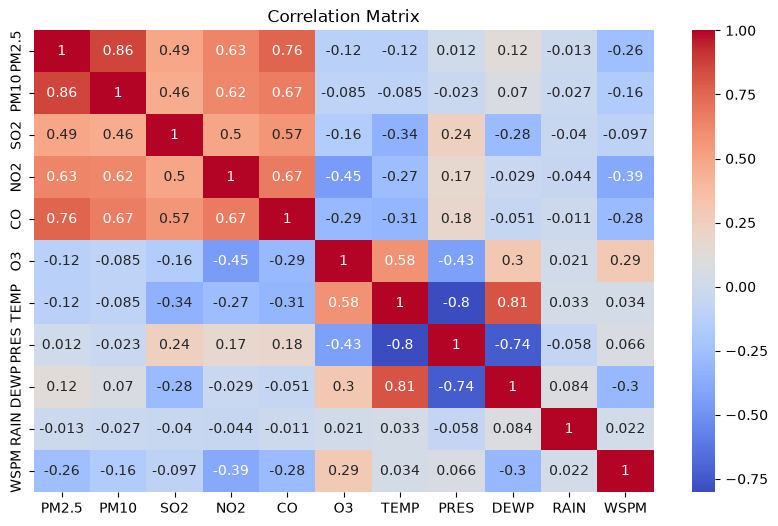

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Heatmap of correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [22]:
# Top 5 most polluted stations by average PM2.5
top_stations = df.groupby('station')['PM2.5'].mean().nlargest(5)

top_stations

station
Dongsi           83.699989
Nongzhanguan     82.531457
Wanshouxigong    82.118718
Wanliu           81.765862
Gucheng          81.700728
Name: PM2.5, dtype: float64

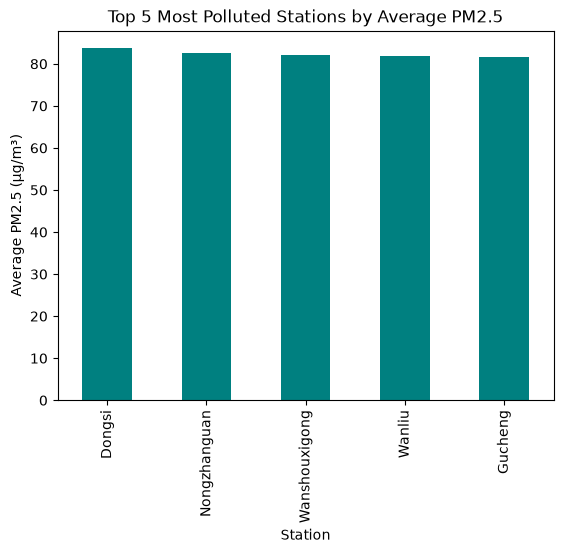

In [23]:
# Plot the bar chart
top_stations.plot(kind='bar', color='teal')
plt.title('Top 5 Most Polluted Stations by Average PM2.5')
plt.xlabel('Station')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

In [24]:
# Monthly PM2.5 trend
monthly_pm25 = df.groupby('month')['PM2.5'].mean()

monthly_pm25

month
1     86.936759
2     93.241699
3     94.465195
4     72.865893
5     63.522398
6     69.303315
7     71.919289
8     53.814345
9     61.877751
10    91.391225
11    93.057924
12    95.569155
Name: PM2.5, dtype: float64

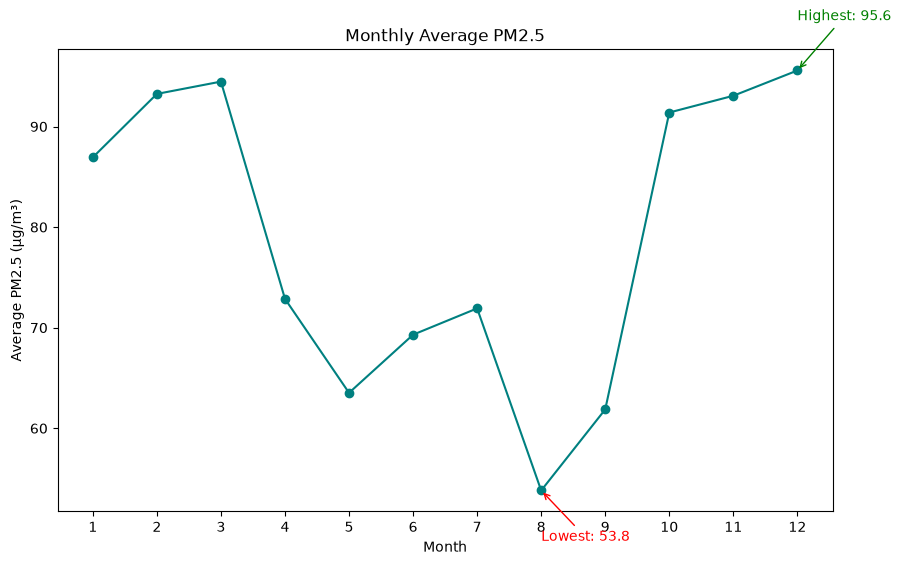

In [25]:
# Plot the line chart
plt.figure(figsize=(10, 6))
monthly_pm25.plot(kind='line', marker='o', color='teal')
plt.title('Monthly Average PM2.5')
plt.xlabel('Month')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.xticks(range(1, 13))

# Annotate highest and lowest months
max_month = monthly_pm25.idxmax()
min_month = monthly_pm25.idxmin()

plt.annotate(
    f'Highest: {monthly_pm25[max_month]:.1f}',
    xy=(max_month, monthly_pm25[max_month]),
    xytext=(max_month, monthly_pm25[max_month] + 5),
    arrowprops=dict(arrowstyle='->', color='green'),
    color='green')

plt.annotate(
    f'Lowest: {monthly_pm25[min_month]:.1f}',
    xy=(min_month, monthly_pm25[min_month]),
    xytext=(min_month, monthly_pm25[min_month] - 5),
    arrowprops=dict(arrowstyle='->', color='red'),
    color='red')

plt.show()

In [26]:
# PM2.5 by station (location)
station_pm25 = df.groupby('station')['PM2.5'].mean().sort_values(ascending=False)

station_pm25

station
Dongsi           83.699989
Nongzhanguan     82.531457
Wanshouxigong    82.118718
Wanliu           81.765862
Gucheng          81.700728
Guanyuan         80.913836
Aotizhongxin     80.884976
Tiantan          79.883529
Shunyi           77.816334
Changping        69.952530
Huairou          69.211694
Dingling         65.512704
Name: PM2.5, dtype: float64

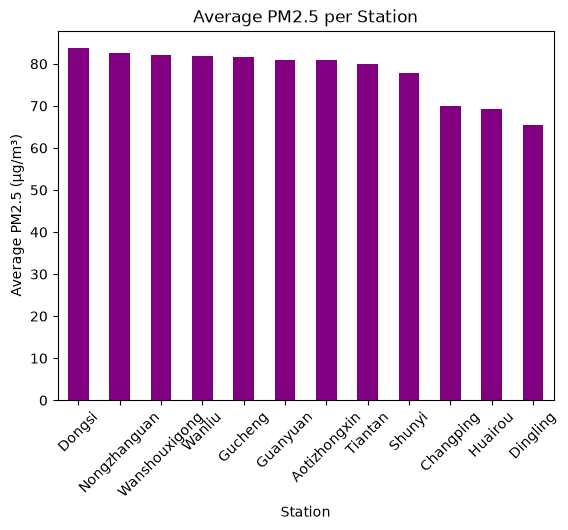

The station with the highest pollution is Dongsi with an average PM2.5 of 83.7.


In [27]:
# Plot the bar chart
station_pm25.plot(kind='bar', color='purple')
plt.title('Average PM2.5 per Station')
plt.xlabel('Station')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.xticks(rotation=45)
plt.show()

# Identify station with highest pollution
worst_station = station_pm25.idxmax()
worst_value = station_pm25.max()
print(f'The station with the highest pollution is {worst_station} with an average PM2.5 of {worst_value:.1f}.')

In [28]:
df

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,DEWP,RAIN,wd,WSPM,station,Date,Datetime,PM25_Category,Rain_Status,Wind_Level
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.000000,...,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01,2013-03-01 00:00:00,Excellent,No Rain,Moderate
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.000000,...,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01,2013-03-01 01:00:00,Excellent,No Rain,Moderate
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.000000,...,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01,2013-03-01 02:00:00,Excellent,No Rain,Moderate
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.000000,...,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01,2013-03-01 03:00:00,Excellent,No Rain,Moderate
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.000000,...,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01,2013-03-01 04:00:00,Excellent,No Rain,Light
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392395,32696,2016,11,22,7,6.0,17.0,3.0,14.0,300.000000,...,-20.2,0.0,NW,4.7,Wanshouxigong,2016-11-22,2016-11-22 07:00:00,Excellent,No Rain,Moderate
392396,32697,2016,11,22,8,11.0,26.0,4.0,23.0,400.000000,...,-20.0,0.0,NW,5.3,Wanshouxigong,2016-11-22,2016-11-22 08:00:00,Excellent,No Rain,Moderate
392397,32698,2016,11,22,9,7.0,23.0,3.0,18.0,400.000000,...,-20.1,0.0,NW,4.7,Wanshouxigong,2016-11-22,2016-11-22 09:00:00,Excellent,No Rain,Moderate
392398,32699,2016,11,22,10,6.0,44.0,4.0,12.0,400.000000,...,-20.0,0.0,NW,5.3,Wanshouxigong,2016-11-22,2016-11-22 10:00:00,Excellent,No Rain,Moderate


In [29]:
# Station profile
station_data = df.groupby('station').agg(
    Fine_Dust=('PM2.5', 'mean'),
    Coarse_Dust=('PM10', 'mean'),
    Traffic_Gas=('NO2', 'mean'),
    Wind_Strength=('WSPM', 'mean'),
    Readings=('No', 'count')
)

station_data

,Fine_Dust,Coarse_Dust,Traffic_Gas,Wind_Strength,Readings
station,,,,,
Aotizhongxin,80.884976,109.090536,57.987465,1.705008,32700
Changping,69.952530,93.976113,43.315984,1.844621,32700
Dingling,65.512704,83.772743,27.386593,1.844621,32700
Dongsi,83.699989,107.249060,52.581716,1.868241,32700
Guanyuan,80.913836,107.112154,56.672247,1.705008,32700
Gucheng,81.700728,117.105830,54.723466,1.294568,32700
Huairou,69.211694,91.241751,32.583935,1.642633,32700
Nongzhanguan,82.531457,106.909607,57.285721,1.868241,32700
Shunyi,77.816334,97.574950,42.903457,1.809566,32700


In [30]:
# Manual classification
def classify_station(row):
    if row['Fine_Dust'] >= 80 and row['Traffic_Gas'] >= 50:
        return 'High Pollution'
    elif row['Fine_Dust'] >= 75:
        return 'Medium Pollution'
    else:
        return 'Low Pollution'

# Apply the function to classify stations
station_data['Category'] = station_data.apply(classify_station, axis=1)

# Count the number of stations in each category
category_counts = station_data['Category'].value_counts()

category_counts

Category
High Pollution      7
Low Pollution       3
Medium Pollution    2
Name: count, dtype: int64

In [31]:
station_data

,Fine_Dust,Coarse_Dust,Traffic_Gas,Wind_Strength,Readings,Category
station,,,,,,
Aotizhongxin,80.884976,109.090536,57.987465,1.705008,32700,High Pollution
Changping,69.952530,93.976113,43.315984,1.844621,32700,Low Pollution
Dingling,65.512704,83.772743,27.386593,1.844621,32700,Low Pollution
Dongsi,83.699989,107.249060,52.581716,1.868241,32700,High Pollution
Guanyuan,80.913836,107.112154,56.672247,1.705008,32700,High Pollution
Gucheng,81.700728,117.105830,54.723466,1.294568,32700,High Pollution
Huairou,69.211694,91.241751,32.583935,1.642633,32700,Low Pollution
Nongzhanguan,82.531457,106.909607,57.285721,1.868241,32700,High Pollution
Shunyi,77.816334,97.574950,42.903457,1.809566,32700,Medium Pollution


High Pollution stations: 7
Medium Pollution stations: 2
Low Pollution stations: 3


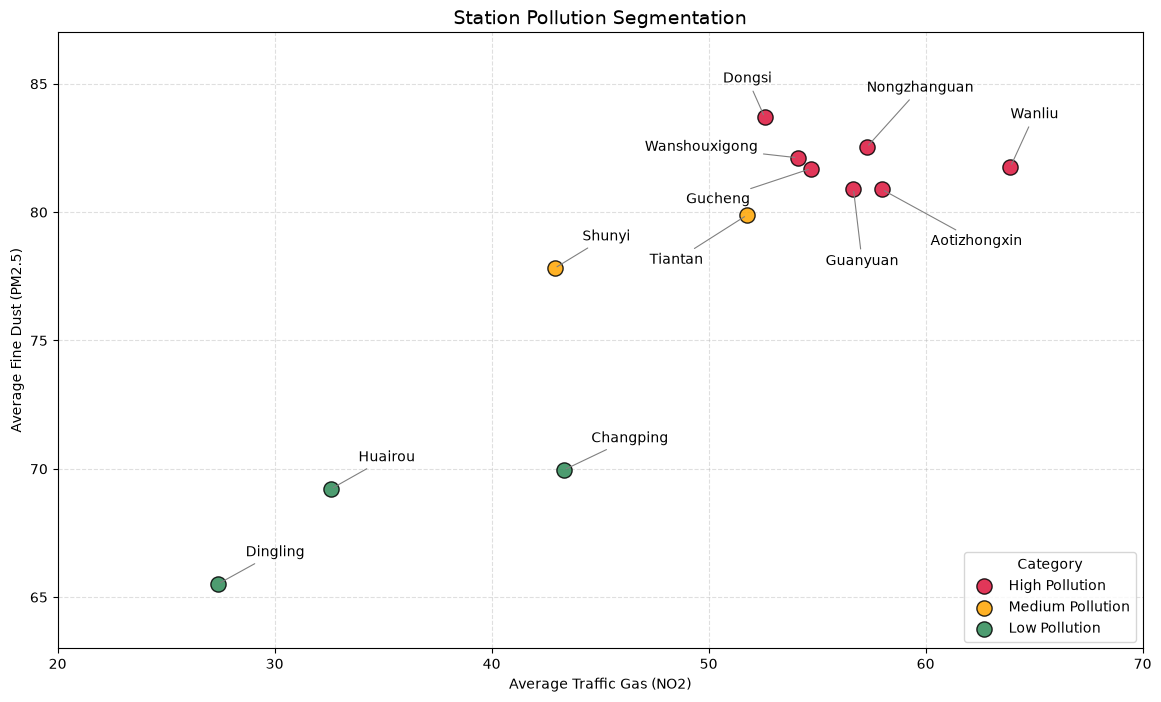

In [32]:
# Scatter plot with arrows (no overlapping names)
colors = {'High Pollution': 'crimson', 'Medium Pollution': 'orange', 'Low Pollution': 'seagreen'}

# Where to put each name (x shift, y shift) - far from the dot, joined by a line
offsets = {'Dongsi': (-30, 25), 'Nongzhanguan': (0, 40), 'Wanshouxigong': (-110, 5),
           'Gucheng': (-90, -25), 'Guanyuan': (-20, -55), 'Aotizhongxin': (35, -40),
           'Wanliu': (0, 35), 'Tiantan': (-70, -35), 'Shunyi': (20, 20),
           'Changping': (20, 20), 'Huairou': (20, 20), 'Dingling': (20, 20)}

plt.figure(figsize=(14, 8))

for label in ['High Pollution', 'Medium Pollution', 'Low Pollution']:
    group = station_data[station_data['Category'] == label]
    print(f'{label} stations: {len(group)}')
    plt.scatter(group['Traffic_Gas'], group['Fine_Dust'], label=label,
                color=colors[label], s=120, edgecolor='black', alpha=0.85, zorder=3)
    for name, row in group.iterrows():
        plt.annotate(name, (row['Traffic_Gas'], row['Fine_Dust']),
                     xytext=offsets.get(name, (15, 15)), textcoords='offset points', fontsize=10,
                     arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))

plt.xlabel('Average Traffic Gas (NO2)')
plt.ylabel('Average Fine Dust (PM2.5)')
plt.title('Station Pollution Segmentation', fontsize=14)
plt.xlim(20, 70)
plt.ylim(63, 87)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Category', loc='lower right')
plt.show()

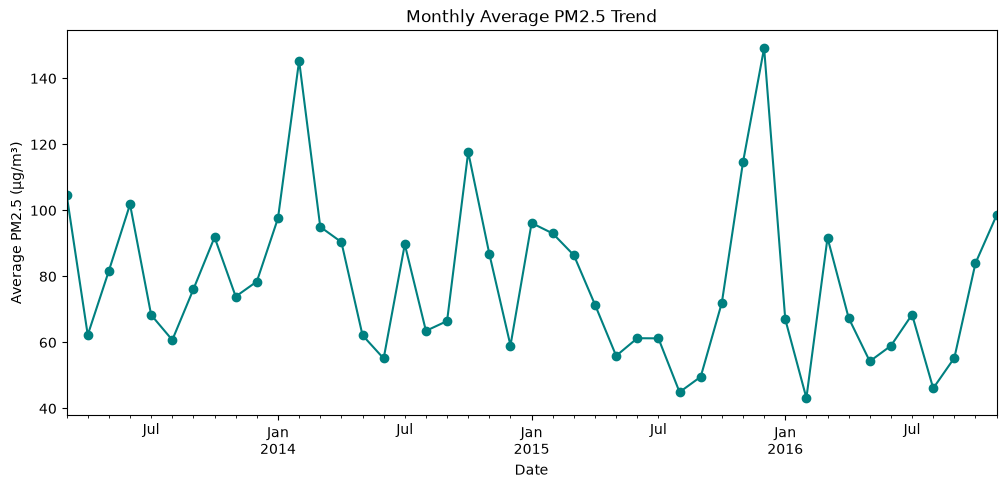

In [33]:
# Monthly PM2.5 trend over the full period (2013-2016)
plt.figure(figsize=(12, 5))
monthly_trend.plot(color='teal', marker='o')
plt.title('Monthly Average PM2.5 Trend')
plt.xlabel('Date')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

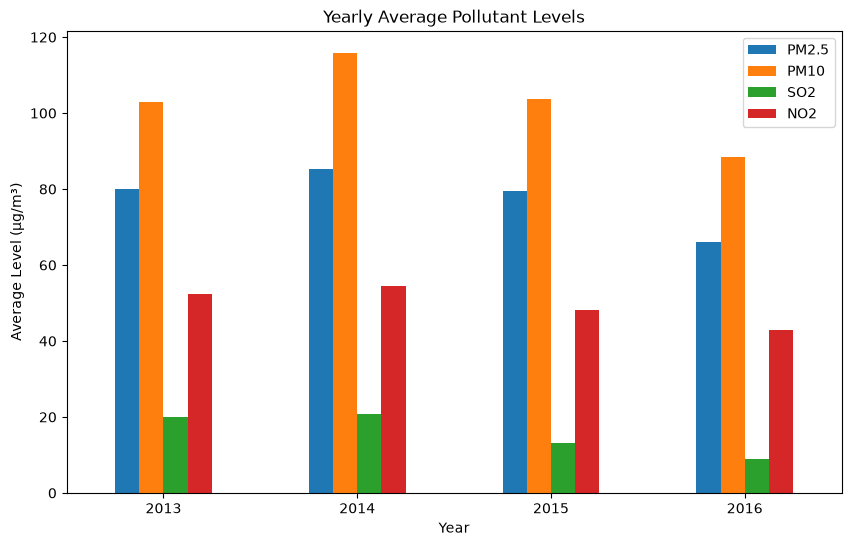

In [34]:
#  Yearly average of pollutants
yearly = df.groupby(df['Date'].dt.year)[['PM2.5', 'PM10', 'SO2', 'NO2']].mean()
yearly.plot(kind='bar', figsize=(10, 6))
plt.title('Yearly Average Pollutant Levels')
plt.xlabel('Year')
plt.ylabel('Average Level (µg/m³)')
plt.xticks(rotation=0)
plt.show()


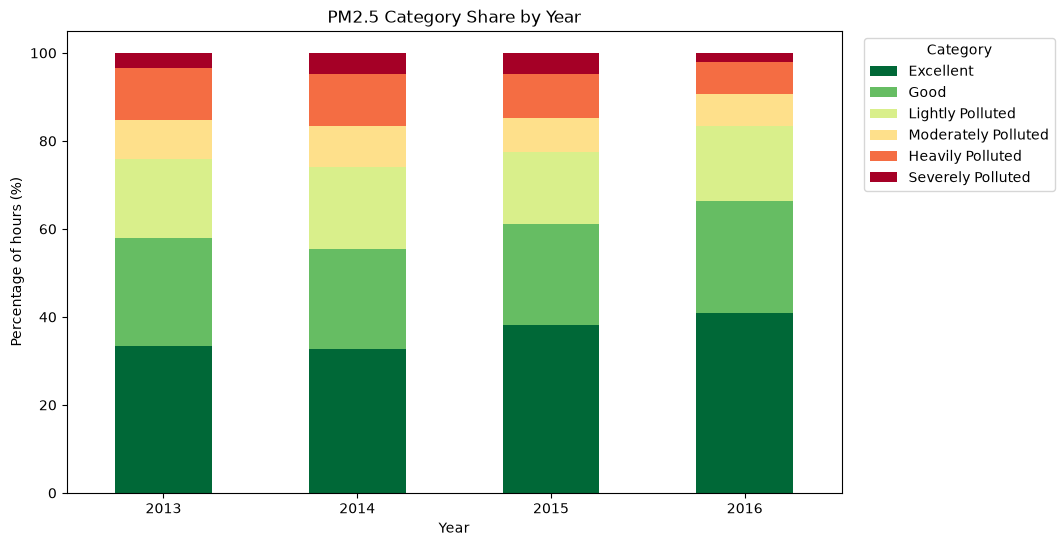

In [35]:
#  Air quality category share per year (stacked bar)
category_share = pd.crosstab(df['Date'].dt.year, df['PM25_Category'], normalize='index') * 100
order = ['Excellent', 'Good', 'Lightly Polluted', 'Moderately Polluted', 'Heavily Polluted', 'Severely Polluted']
category_share[order].plot(kind='bar', stacked=True, figsize=(10, 6), colormap='RdYlGn_r')
plt.title('PM2.5 Category Share by Year')
plt.xlabel('Year')
plt.ylabel('Percentage of hours (%)')
plt.xticks(rotation=0)
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

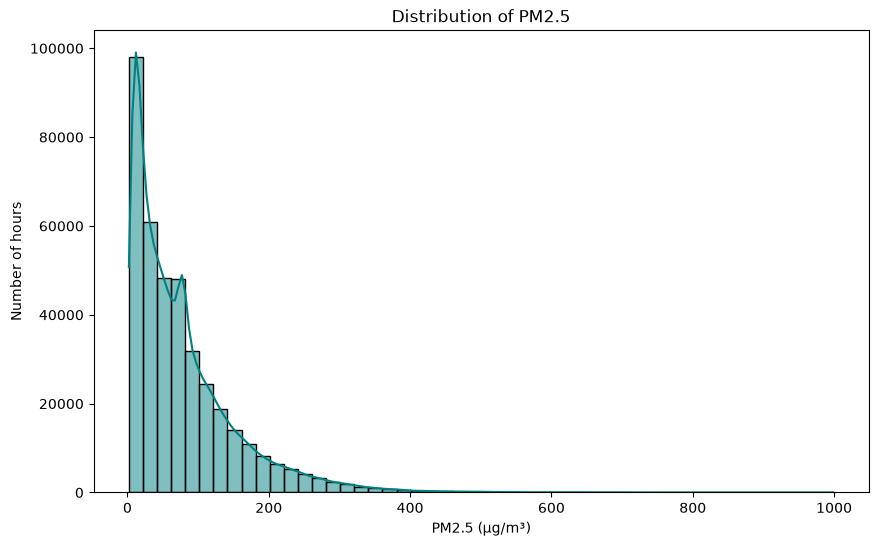

In [36]:
#  Distribution of PM2.5 (Seaborn)
plt.figure(figsize=(10, 6))
sns.histplot(df['PM2.5'], bins=50, kde=True, color='teal')
plt.title('Distribution of PM2.5')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Number of hours')
plt.show()

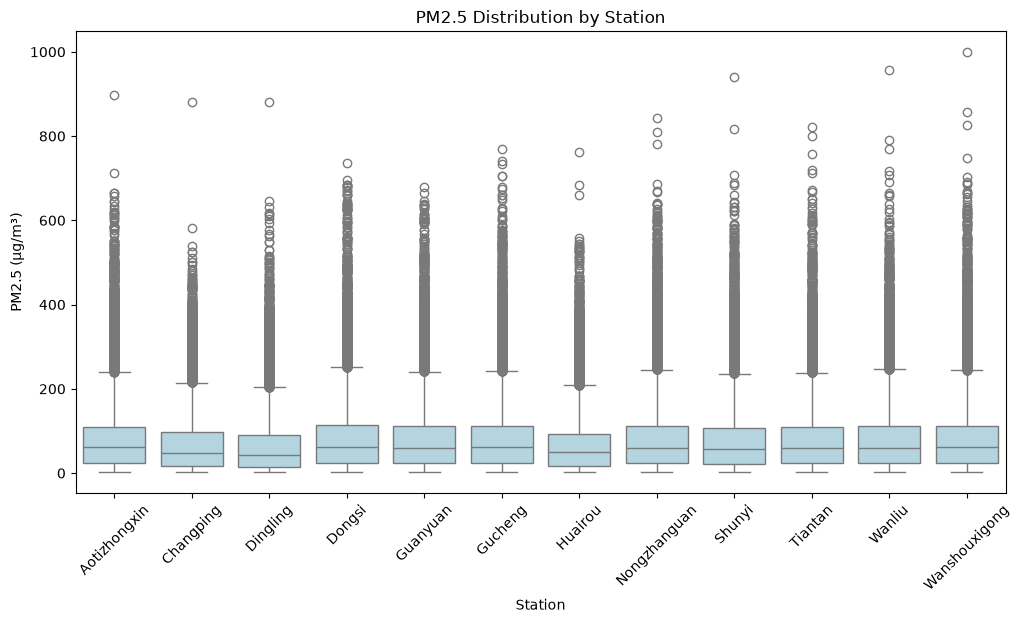

In [37]:
#  PM2.5 by station (Seaborn boxplot)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='station', y='PM2.5', color='lightblue')
plt.title('PM2.5 Distribution by Station')
plt.xlabel('Station')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(rotation=45)
plt.show()

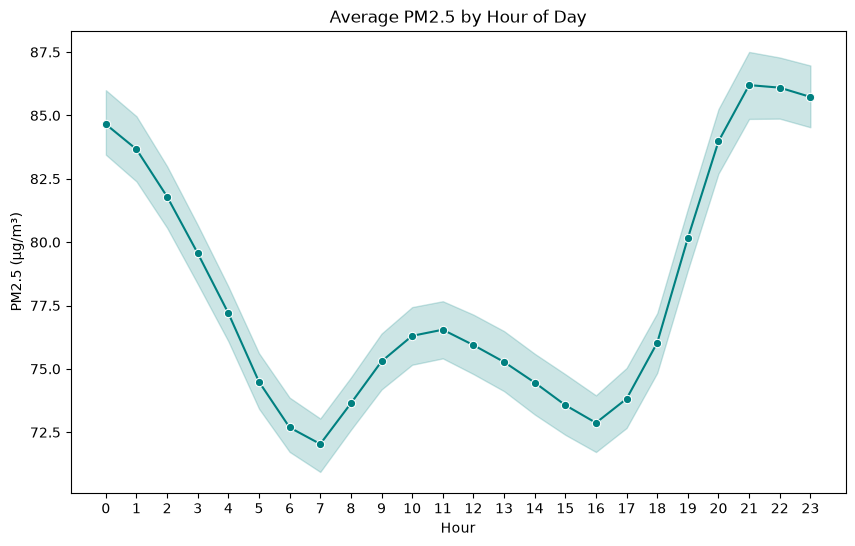

In [38]:
#  Hourly pattern: PM2.5 by hour of day (Seaborn)
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='hour', y='PM2.5', marker='o', color='teal')
plt.title('Average PM2.5 by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(range(0, 24))
plt.show()

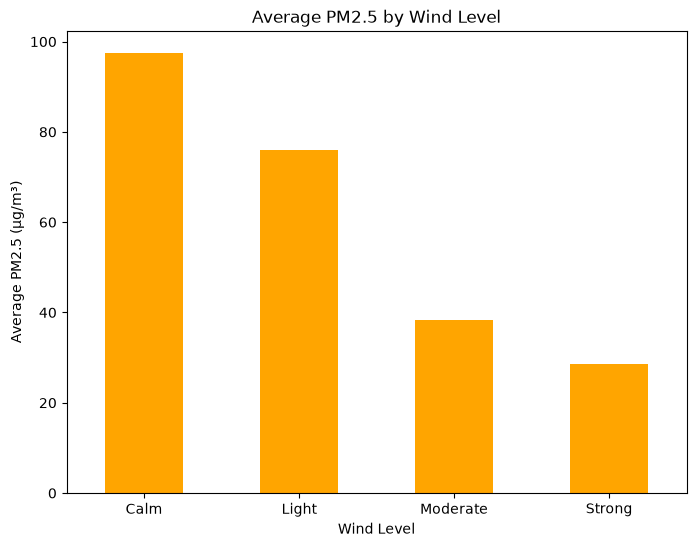

In [39]:
#  Wind speed vs PM2.5 (weather relationship)
wind_pm25 = df.groupby('Wind_Level', observed=True)['PM2.5'].mean()
wind_pm25.plot(kind='bar', color='orange', figsize=(8, 6))
plt.title('Average PM2.5 by Wind Level')
plt.xlabel('Wind Level')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.xticks(rotation=0)
plt.show()


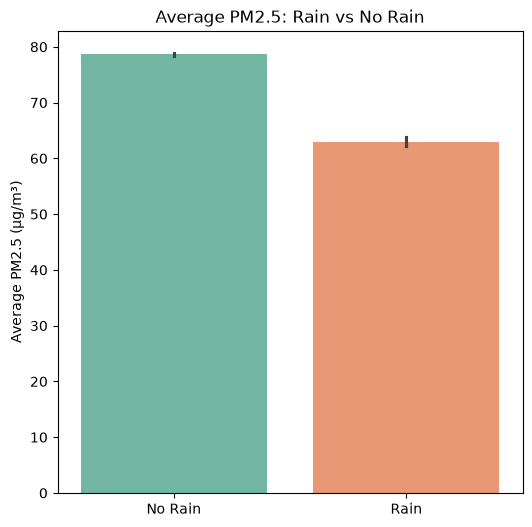

In [40]:
#  Rain vs No Rain (weather relationship)
plt.figure(figsize=(6, 6))
sns.barplot(data=df, x='Rain_Status', y='PM2.5', hue='Rain_Status', palette='Set2', legend=False)
plt.title('Average PM2.5: Rain vs No Rain')
plt.xlabel('')
plt.ylabel('Average PM2.5 (µg/m³)')
plt.show()

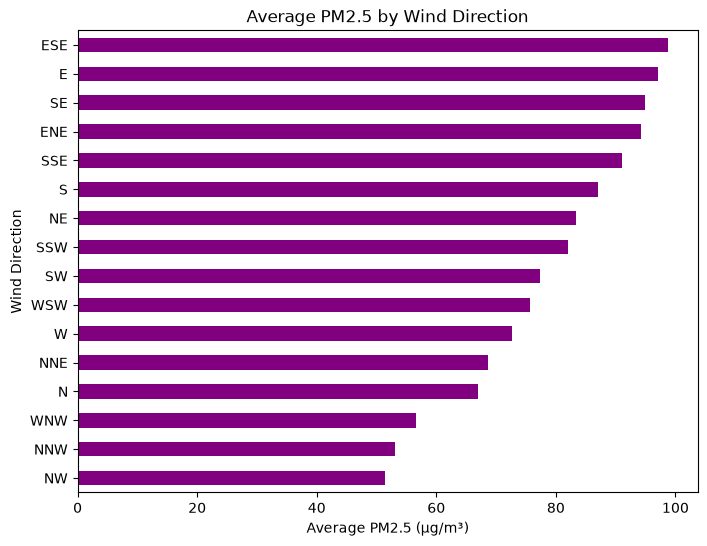

In [41]:
# Wind direction vs PM2.5
wd_pm25 = df.groupby('wd')['PM2.5'].mean().sort_values()
wd_pm25.plot(kind='barh', color='purple', figsize=(8, 6))
plt.title('Average PM2.5 by Wind Direction')
plt.xlabel('Average PM2.5 (µg/m³)')
plt.ylabel('Wind Direction')
plt.show()

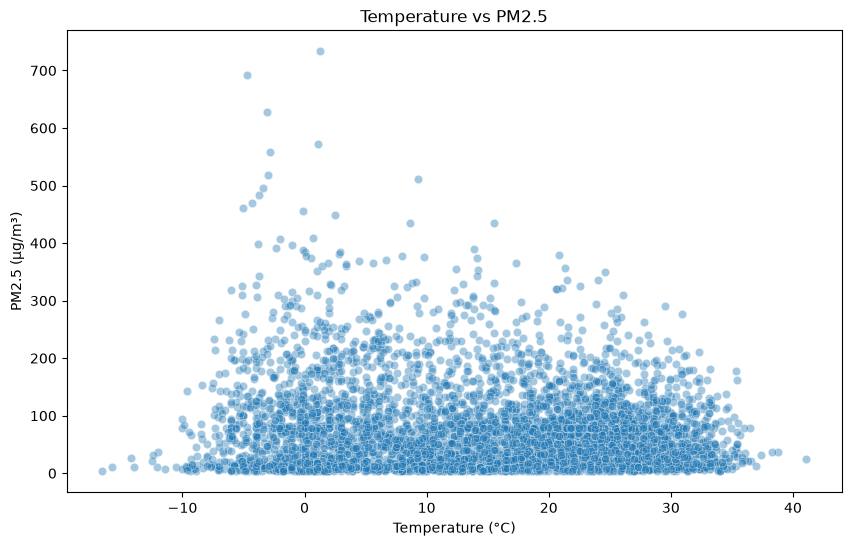

In [42]:
#  Temperature vs PM2.5 (scatter on a sample for speed)
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x='TEMP', y='PM2.5', alpha=0.4)
plt.title('Temperature vs PM2.5')
plt.xlabel('Temperature (°C)')
plt.ylabel('PM2.5 (µg/m³)')
plt.show()

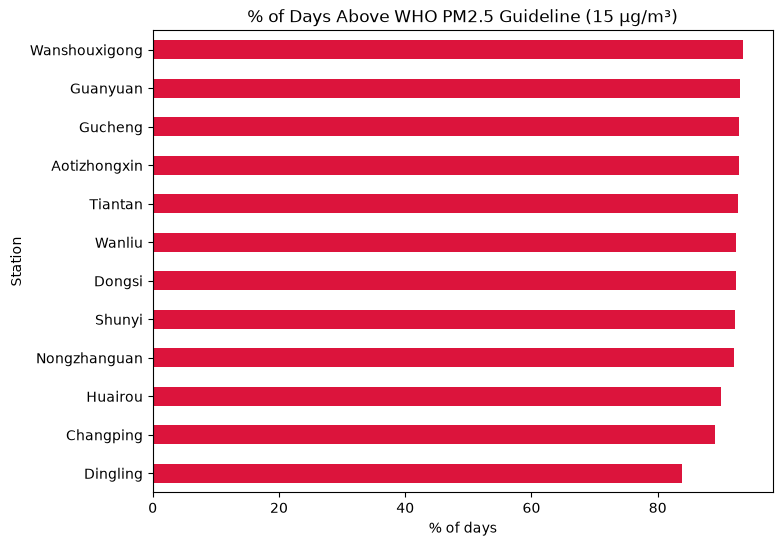

In [43]:
#  Public health: % of days above WHO guideline (15 µg/m³) per station
unsafe_pct = daily.groupby('station')['Unsafe'].mean() * 100
unsafe_pct.sort_values().plot(kind='barh', color='crimson', figsize=(8, 6))
plt.title('% of Days Above WHO PM2.5 Guideline (15 µg/m³)')
plt.xlabel('% of days')
plt.ylabel('Station')
plt.show()

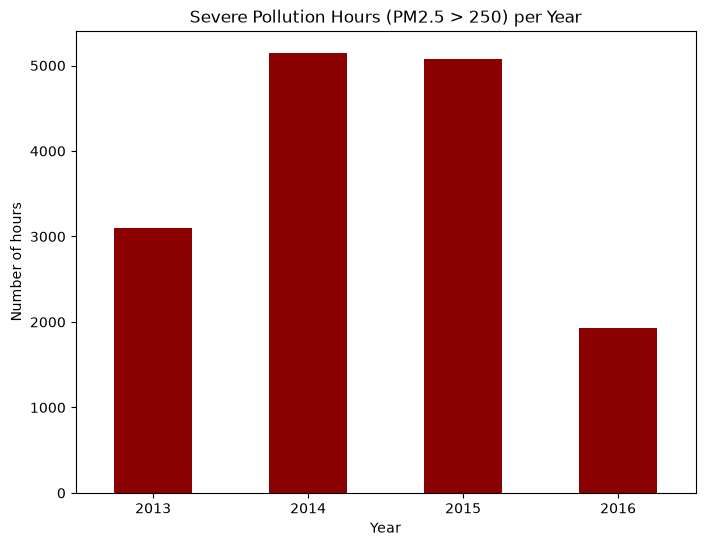

In [44]:
#  Public health: severe pollution hours (PM2.5 > 250) per year
severe = df[df['PM2.5'] > 250].groupby(df['Date'].dt.year).size()
severe.plot(kind='bar', color='darkred', figsize=(8, 6))
plt.title('Severe Pollution Hours (PM2.5 > 250) per Year')
plt.xlabel('Year')
plt.ylabel('Number of hours')
plt.xticks(rotation=0)
plt.show()

In [45]:
sns.set_style('whitegrid')

daily_aqi = (df.groupby(['station', 'Date'])
               .agg(PM25=('PM2.5', 'mean'), PM10=('PM10', 'mean'), SO2=('SO2', 'mean'),
                    NO2=('NO2', 'mean'), CO=('CO', 'mean'), O3=('O3', 'mean'),
                    TEMP=('TEMP', 'mean'), PRES=('PRES', 'mean'), DEWP=('DEWP', 'mean'),
                    RAIN=('RAIN', 'sum'), WSPM=('WSPM', 'mean'))
               .reset_index())

sub25 = np.interp(daily_aqi['PM25'], [0, 30, 60, 90, 120, 250, 380], [0, 50, 100, 200, 300, 400, 500])
sub10 = np.interp(daily_aqi['PM10'], [0, 50, 100, 250, 350, 430, 550], [0, 50, 100, 200, 300, 400, 500])
daily_aqi['AQI'] = np.fmax(sub25, sub10)

categories = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
daily_aqi['Category'] = pd.cut(daily_aqi['AQI'], bins=[-1, 50, 100, 200, 300, 400, 1000], labels=categories)

daily_aqi['Year'] = daily_aqi['Date'].dt.year
daily_aqi['Month'] = daily_aqi['Date'].dt.month
daily_aqi['YearMonth'] = daily_aqi['Date'].dt.to_period('M').dt.to_timestamp()

def get_season(m):
    if m in [12, 1, 2]: return 'Winter'
    if m in [3, 4, 5]:  return 'Spring'
    if m in [6, 7, 8]:  return 'Summer'
    return 'Autumn'

daily_aqi['Season'] = daily_aqi['Month'].apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

print('Daily rows:', daily_aqi.shape[0])
daily_aqi.head()

Daily rows: 16356


,station,Date,PM25,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,AQI,Category,Year,Month,YearMonth,Season
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,1026.875000,-18.745833,0.0,3.254167,11.875000,Good,2013,3,2013-03-01,Spring
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1026.850000,-15.937500,0.0,1.479167,51.250000,Satisfactory,2013,3,2013-03-01,Spring
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1014.608333,-12.316667,0.0,1.658333,156.388889,Moderate,2013,3,2013-03-01,Spring
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.570830,47.066710,640.943384,53.750000,9.962500,1017.650000,-11.683333,0.0,2.404167,44.583333,Good,2013,3,2013-03-01,Spring
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1010.900000,-7.525000,0.0,1.129167,322.211538,Very Poor,2013,3,2013-03-01,Spring


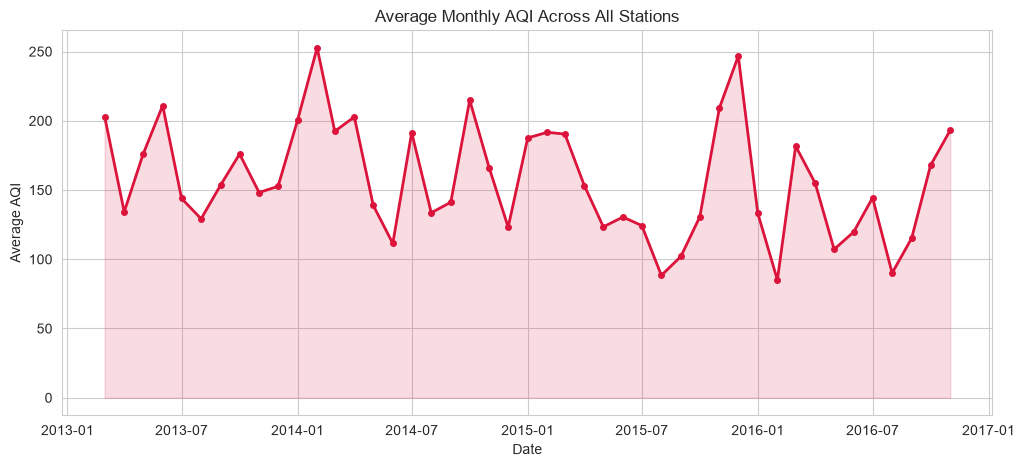

In [46]:
# Monthly AQI trend
monthly_aqi = daily_aqi.groupby('YearMonth')['AQI'].mean()
plt.figure(figsize=(12, 5))
plt.plot(monthly_aqi.index, monthly_aqi.values, color='crimson', linewidth=2, marker='o', markersize=4)
plt.fill_between(monthly_aqi.index, monthly_aqi.values, alpha=0.15, color='crimson')
plt.title('Average Monthly AQI Across All Stations')
plt.xlabel('Date'); plt.ylabel('Average AQI')
plt.show()

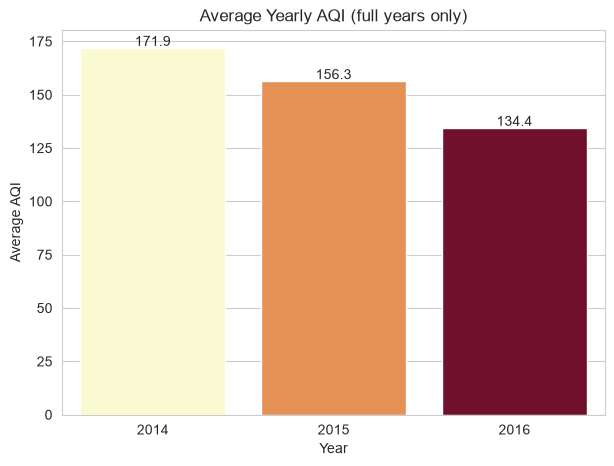

In [47]:
# Yearly AQI (2013 starts in March and 2017 is partial, so only full years 2014-2016)
full = daily_aqi[daily_aqi['Year'].between(2014, 2016)]
yearly_aqi = full.groupby('Year')['AQI'].mean().round(1)
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=yearly_aqi.index, y=yearly_aqi.values, hue=yearly_aqi.index, palette='YlOrRd', legend=False)
for i, v in enumerate(yearly_aqi.values):
    ax.text(i, v + 1, str(v), ha='center')
plt.title('Average Yearly AQI (full years only)')
plt.ylabel('Average AQI')
plt.show()

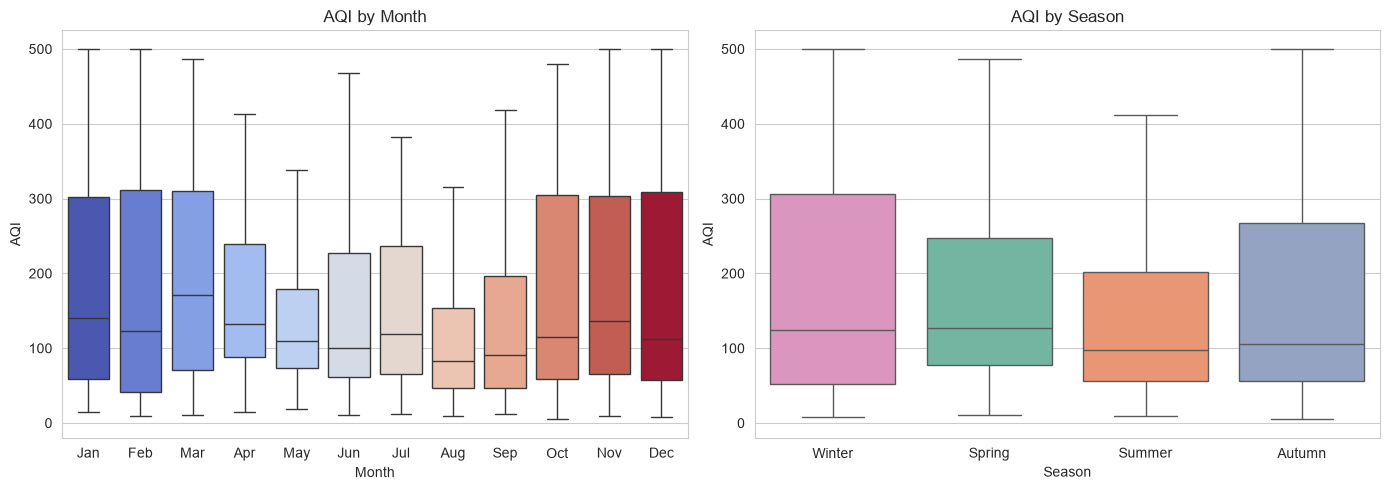

Season
Winter    174.4
Spring    163.2
Summer    134.7
Autumn    159.2
Name: AQI, dtype: float64


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=daily_aqi, x='Month', y='AQI', hue='Month', palette='coolwarm', legend=False, showfliers=False, ax=axes[0])
axes[0].set_xticks(range(12)); axes[0].set_xticklabels(month_names)
axes[0].set_title('AQI by Month')
sns.boxplot(data=daily_aqi, x='Season', y='AQI', order=season_order, hue='Season', palette='Set2', legend=False, showfliers=False, ax=axes[1])
axes[1].set_title('AQI by Season')
plt.tight_layout()
plt.show()

print(daily_aqi.groupby('Season')['AQI'].mean().reindex(season_order).round(1))

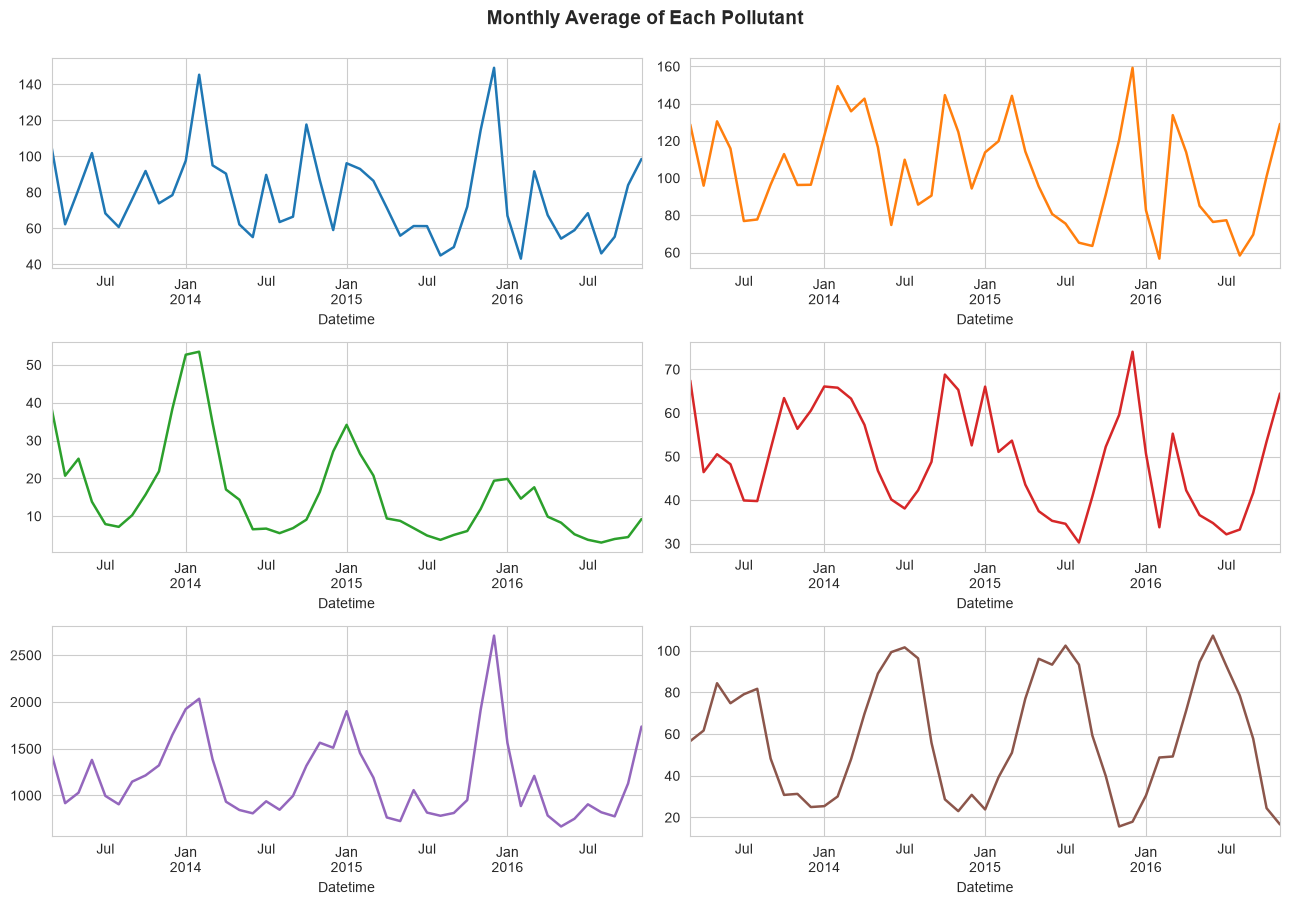

In [49]:
monthly_poll = df.groupby(df['Datetime'].dt.to_period('M'))[pollutants].mean()
monthly_poll.index = monthly_poll.index.to_timestamp()

monthly_poll.plot(subplots=True, layout=(3, 2), figsize=(13, 9), legend=False, linewidth=1.8, sharex=False)
plt.suptitle('Monthly Average of Each Pollutant', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()

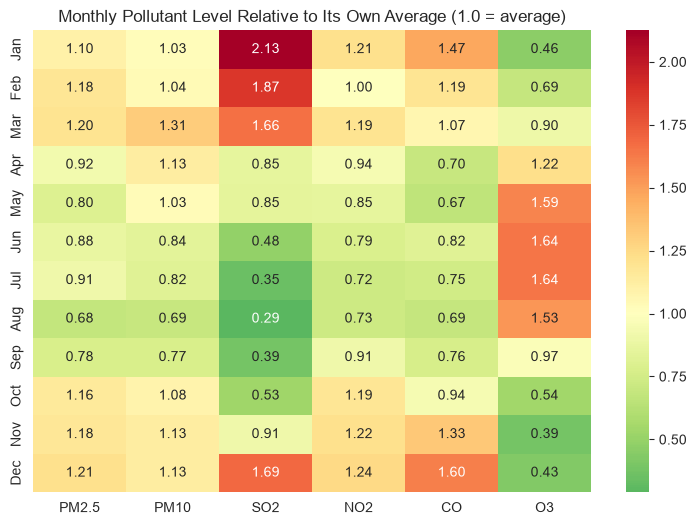

In [50]:
# Which pollutant peaks in which month (each divided by its own average)
month_poll = df.groupby('month')[pollutants].mean()
index_poll = month_poll / month_poll.mean()
plt.figure(figsize=(9, 6))
sns.heatmap(index_poll, annot=True, fmt='.2f', cmap='RdYlGn_r', center=1, yticklabels=month_names)
plt.title('Monthly Pollutant Level Relative to Its Own Average (1.0 = average)')
plt.xlabel(''); plt.ylabel('')
plt.show()

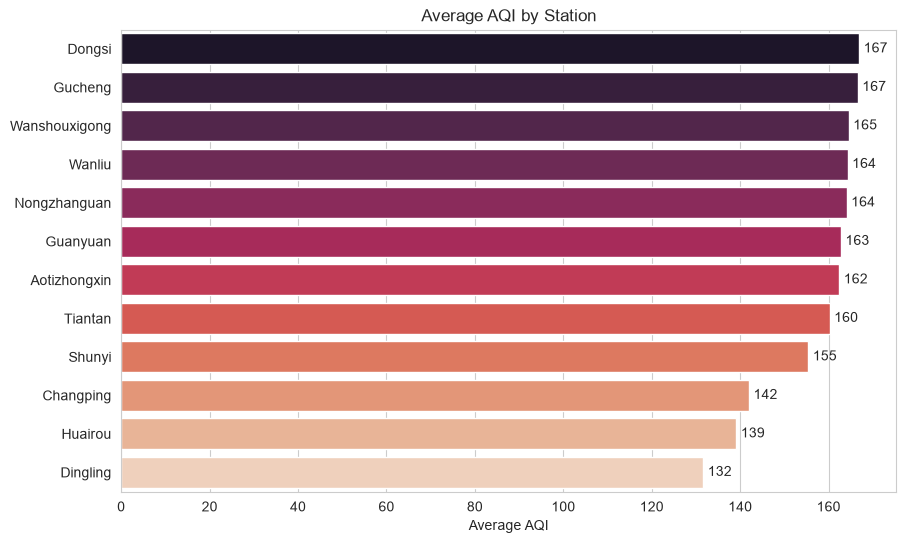

Most polluted : Dongsi 166.9
Least polluted: Dingling 131.7


In [51]:
station_mean = daily_aqi.groupby('station')['AQI'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=station_mean.values, y=station_mean.index, hue=station_mean.index, palette='rocket', legend=False)
for i, v in enumerate(station_mean.values):
    ax.text(v + 1, i, str(round(v)), va='center')
plt.title('Average AQI by Station')
plt.xlabel('Average AQI'); plt.ylabel('')
plt.show()
print('Most polluted :', station_mean.index[0], round(station_mean.iloc[0], 1))
print('Least polluted:', station_mean.index[-1], round(station_mean.iloc[-1], 1))

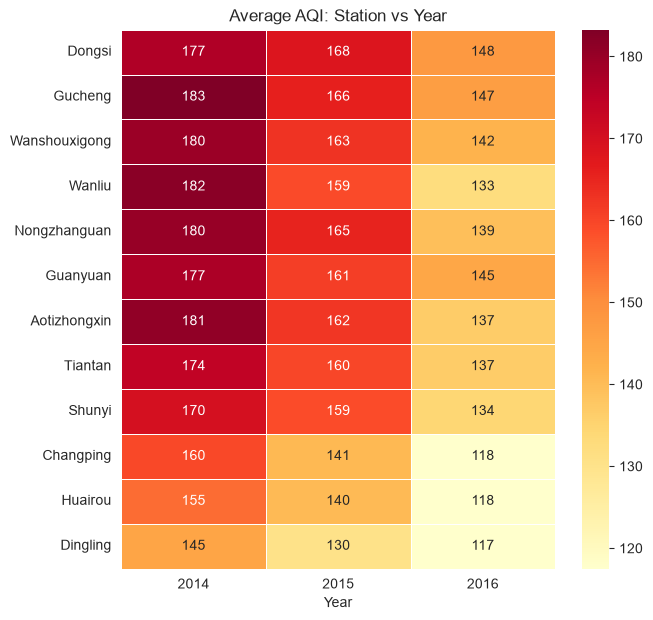

In [52]:
# Station vs Year heatmap (full years)
heat = full.pivot_table(index='station', columns='Year', values='AQI').loc[station_mean.index]
plt.figure(figsize=(7, 7))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5)
plt.title('Average AQI: Station vs Year')
plt.ylabel('')
plt.show()

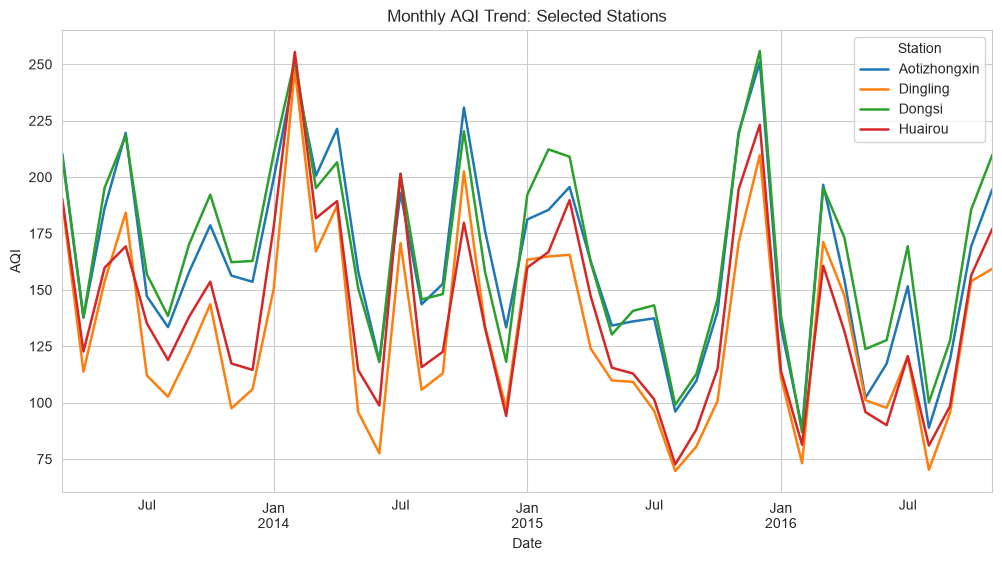

In [53]:
# Monthly AQI trend: most polluted, least polluted and two other stations
selected = list(dict.fromkeys([station_mean.index[0], station_mean.index[-1], 'Aotizhongxin', 'Huairou']))
sel = daily_aqi[daily_aqi['station'].isin(selected)]
sel.pivot_table(index='YearMonth', columns='station', values='AQI').plot(figsize=(12, 6), linewidth=1.8)
plt.title('Monthly AQI Trend: Selected Stations')
plt.xlabel('Date'); plt.ylabel('AQI')
plt.legend(title='Station')
plt.show()

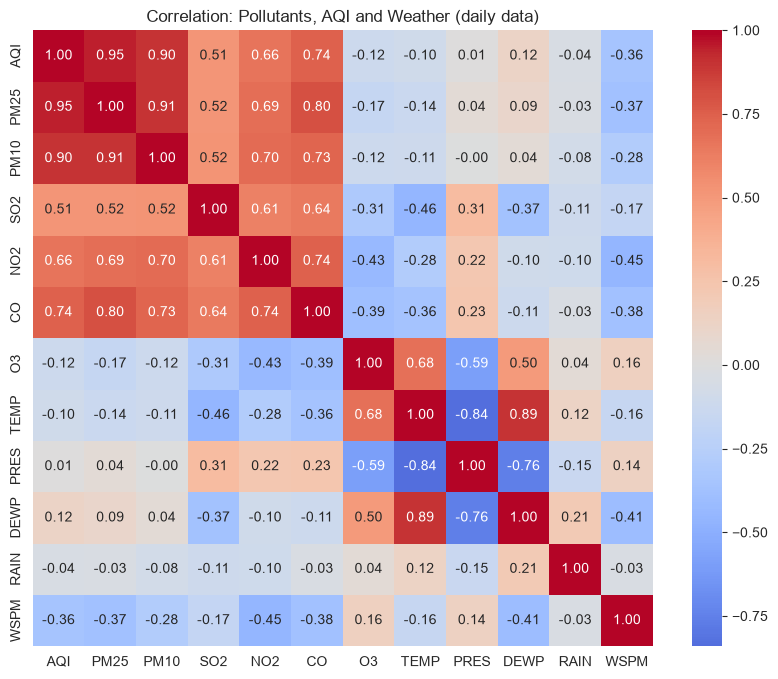

PM25    0.95
PM10    0.90
CO      0.74
NO2     0.66
SO2     0.51
DEWP    0.12
PRES    0.01
RAIN   -0.04
TEMP   -0.10
O3     -0.12
WSPM   -0.36
Name: AQI, dtype: float64

In [54]:
cols = ['AQI', 'PM25', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
plt.figure(figsize=(10, 8))
sns.heatmap(daily_aqi[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation: Pollutants, AQI and Weather (daily data)')
plt.show()

daily_aqi[cols].corr()['AQI'].drop('AQI').sort_values(ascending=False).round(2)

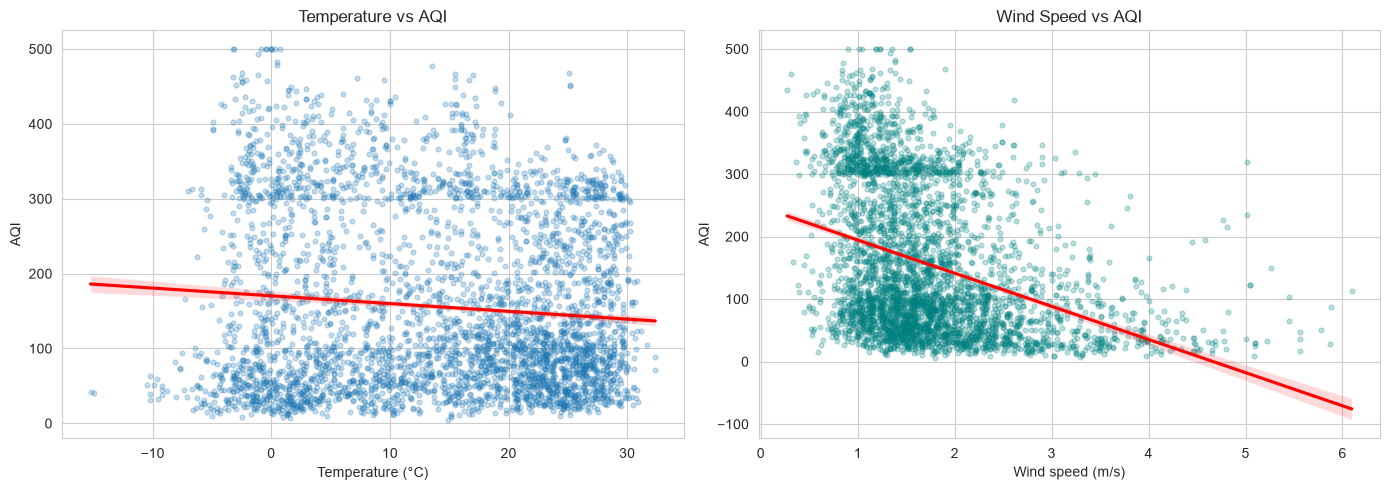

In [55]:
# Temperature and wind speed vs AQI (sample keeps the plot readable)
smp = daily_aqi.sample(4000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=smp, x='TEMP', y='AQI', scatter_kws={'alpha': 0.25, 's': 12}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Temperature vs AQI'); axes[0].set_xlabel('Temperature (°C)')
sns.regplot(data=smp, x='WSPM', y='AQI', scatter_kws={'alpha': 0.25, 's': 12, 'color': 'teal'}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Wind Speed vs AQI'); axes[1].set_xlabel('Wind speed (m/s)')
plt.tight_layout()
plt.show()

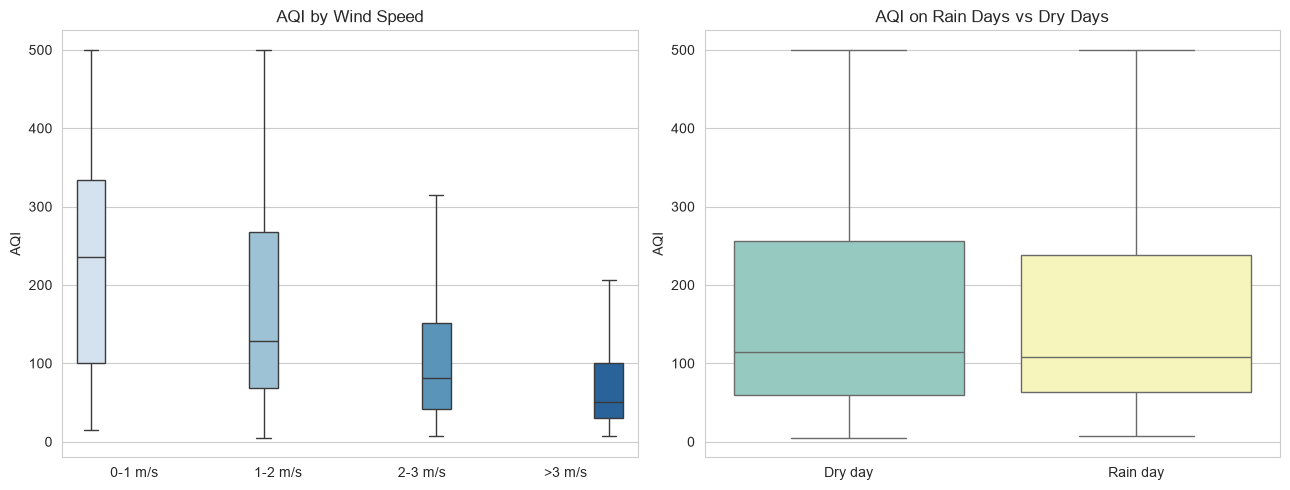

Wind_Group
0-1 m/s    228.0
1-2 m/s    167.0
2-3 m/s    111.0
>3 m/s      74.0
Name: AQI, dtype: float64
Rain_Day
Dry day     159.0
Rain day    150.0
Name: AQI, dtype: float64


In [56]:
# Wind speed groups and rain vs dry days
daily_aqi['Wind_Group'] = pd.cut(daily_aqi['WSPM'], bins=[-0.1, 1, 2, 3, 20],
                                 labels=['0-1 m/s', '1-2 m/s', '2-3 m/s', '>3 m/s'])
daily_aqi['Rain_Day'] = np.where(daily_aqi['RAIN'] > 0, 'Rain day', 'Dry day')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=daily_aqi, x='Wind_Group', y='AQI', hue='Wind_Group', palette='Blues', legend=False, showfliers=False, ax=axes[0])
axes[0].set_title('AQI by Wind Speed'); axes[0].set_xlabel('')
sns.boxplot(data=daily_aqi, x='Rain_Day', y='AQI', hue='Rain_Day', palette='Set3', legend=False, showfliers=False, ax=axes[1])
axes[1].set_title('AQI on Rain Days vs Dry Days'); axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

print(daily_aqi.groupby('Wind_Group', observed=True)['AQI'].mean().round(0))
print(daily_aqi.groupby('Rain_Day')['AQI'].mean().round(0))

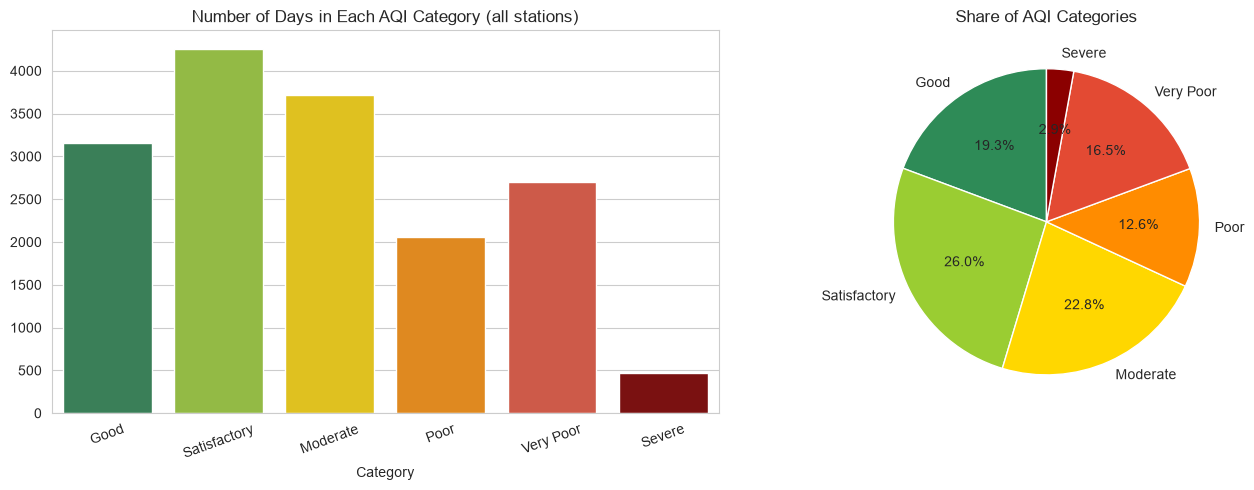

In [57]:
colors = ['#2e8b57', '#9acd32', '#ffd700', '#ff8c00', '#e34a33', '#8b0000']
cat = daily_aqi['Category'].value_counts().reindex(categories)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=cat.index, y=cat.values, hue=cat.index, palette=colors, legend=False, ax=axes[0])
axes[0].set_title('Number of Days in Each AQI Category (all stations)')
axes[0].tick_params(axis='x', rotation=20)
axes[1].pie(cat.values, labels=cat.index, colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Share of AQI Categories')
plt.tight_layout()
plt.show()

Unhealthy days overall: 31.9%


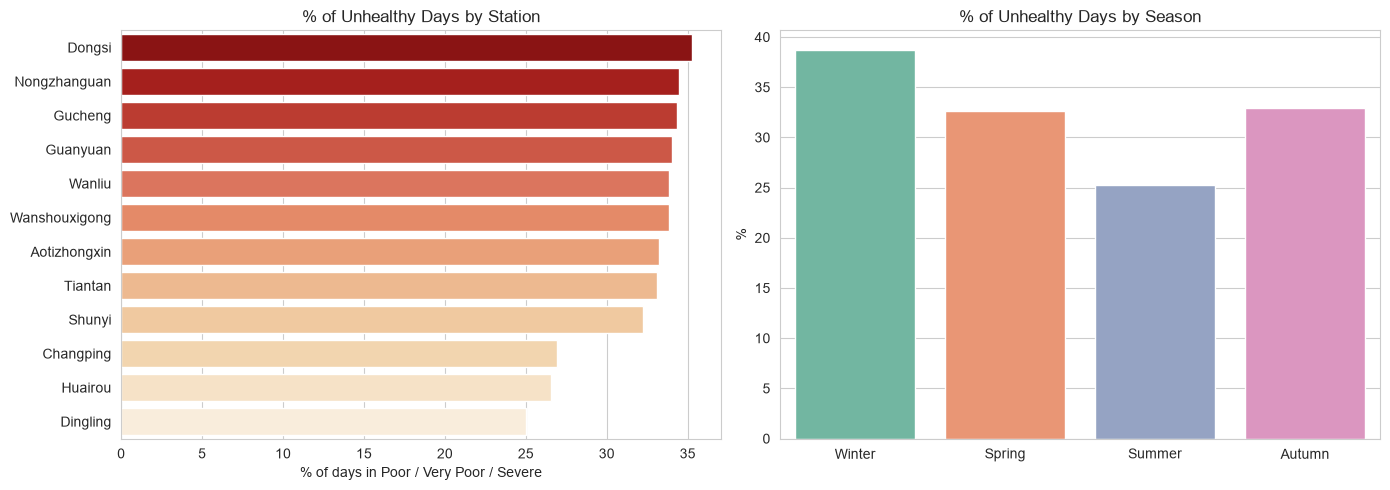

In [58]:
daily_aqi['Unhealthy'] = daily_aqi['Category'].isin(['Poor', 'Very Poor', 'Severe'])
print('Unhealthy days overall: %.1f%%' % (daily_aqi['Unhealthy'].mean() * 100))

unh_station = (daily_aqi.groupby('station')['Unhealthy'].mean() * 100).sort_values(ascending=False)
unh_season = (daily_aqi.groupby('Season')['Unhealthy'].mean() * 100).reindex(season_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=unh_station.values, y=unh_station.index, hue=unh_station.index, palette='OrRd_r', legend=False, ax=axes[0])
axes[0].set_title('% of Unhealthy Days by Station')
axes[0].set_xlabel('% of days in Poor / Very Poor / Severe'); axes[0].set_ylabel('')
sns.barplot(x=unh_season.index, y=unh_season.values, hue=unh_season.index, palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('% of Unhealthy Days by Season'); axes[1].set_ylabel('%'); axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

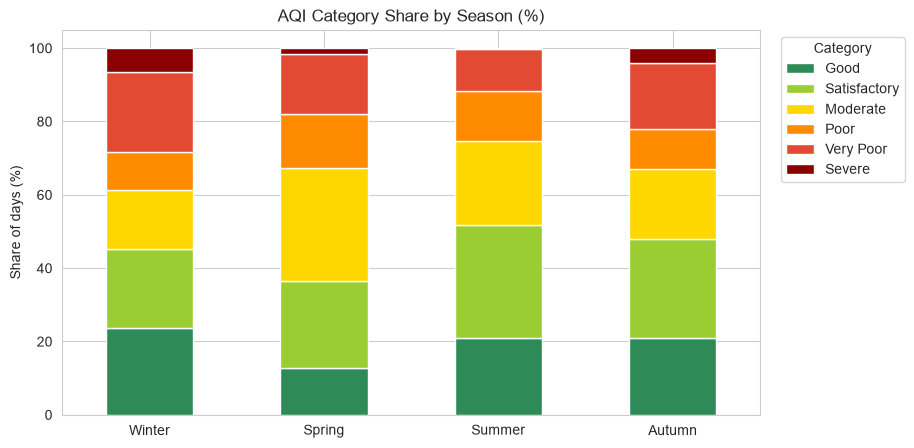

In [59]:
# Category mix for each season
mix = pd.crosstab(daily_aqi['Season'], daily_aqi['Category'], normalize='index').reindex(index=season_order, columns=categories, fill_value=0) * 100
mix.plot(kind='bar', stacked=True, color=colors, figsize=(9, 5))
plt.title('AQI Category Share by Season (%)')
plt.ylabel('Share of days (%)'); plt.xlabel('')
plt.xticks(rotation=0)
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()